# Chapter 15: Averages

Checks [chapter 15](../../book/15-averages.md). Every model here is an average, so there is no training and nothing
to fit: attention heads are `softmax(scores) @ values` on one-dimensional tokens, the ensemble is a weighted sum of
predictions, the denoiser is the attention head of `Averaging.lean`, and the model in claim 4 is **linear in its
weights** (the features are fixed, the weights start at zero, and the loss is `0.5 * sum(residual ** 2)`). Everything
is NumPy in float64, seeded. These are measurements, not proofs: the proofs are in `Attention.lean`,
`AttentionRate.lean`, `Averaging.lean`, `Counting.lean`, `Temperature.lean`, `HardChoices.lean` and `Neighbours.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 15


def get_softmax(scores):
    """Shares along the last axis: positive, adding up to one."""
    shifted = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return shifted / shifted.sum(axis=-1, keepdims=True)


def apply_attention_layer(tokens, score_matrix):
    """Every token is a query: row `query` of `score_matrix` scores every token, output is the blend of the tokens."""
    return get_softmax(score_matrix) @ tokens

## Claim 1: an average never leaves the region its inputs span (`attend_mem_convexHull`, `iterate_attentionLayer_mem`)

Prediction: for 2000 random heads (values uniform in [-5, 5], scores of any size up to 30) the output lies between the
smallest and the largest value. For 300 stacks of 20 layers, with scores that change from layer to layer and depend on
the tokens arbitrarily, no token ever leaves the interval the tokens started in. One failure of either would count against
the claim. The control breaks the hypothesis that the shares add up to one: use `exp(scores / 10)` as weights without dividing
by their sum. Then outputs must leave the interval often.

In [2]:
generator = np.random.default_rng(SEED)
head_outside = 0
unnormalised_outside = 0
head_count = 2000
for trial in range(head_count):
    values = generator.uniform(-5, 5, size=int(generator.integers(2, 12)))
    scores = generator.uniform(-30, 30, size=len(values))
    output = get_softmax(scores) @ values
    head_outside += not (values.min() - 1e-12 <= output <= values.max() + 1e-12)
    unnormalised = np.exp(scores / 10) @ values          # shares that do not add up to one
    unnormalised_outside += not (values.min() <= unnormalised <= values.max())
report("2000 random heads: the output is between the smallest and the largest value", head_outside == 0,
       f"{head_outside} of {head_count} outside")

stack_escapes = 0
largest_overshoot = 0.0
for trial in range(300):
    tokens = generator.uniform(-5, 5, size=12)
    low, high = tokens.min(), tokens.max()
    stack_overshoot = 0.0
    for layer in range(20):
        tokens = apply_attention_layer(tokens, generator.uniform(-30, 30, size=(12, 12)))
        stack_overshoot = max(stack_overshoot, low - tokens.min(), tokens.max() - high)
    stack_escapes += stack_overshoot > 1e-12
    largest_overshoot = max(largest_overshoot, stack_overshoot)
report("300 stacks of 20 layers with arbitrary scores: no token leaves the starting interval", stack_escapes == 0,
       f"largest overshoot {largest_overshoot:.1e}")
report("control: weights not divided by their sum leave the interval (the check can fail)",
       unnormalised_outside > head_count // 4, f"{unnormalised_outside} of {head_count} outside")

[PASS] 2000 random heads: the output is between the smallest and the largest value  (0 of 2000 outside)
[PASS] 300 stacks of 20 layers with arbitrary scores: no token leaves the starting interval  (largest overshoot 0.0e+00)
[PASS] control: weights not divided by their sum leave the interval (the check can fail)  (1756 of 2000 outside)


True

## Claim 2: depth merges the tokens at the rate `(1 - exp(-2 * score_bound)) ** depth` (`abs_iterate_attentionLayer_sub_le`)

Take `score_bound = 0.5`, so one layer keeps at most the factor `1 - exp(-1) = 0.632` of the spread, and 24 tokens in one
dimension. Two kinds of scores, every one of size at most `score_bound`: **random** (uniform in `[-0.5, 0.5]`, new at each
layer) and **stubborn** (a query scores `+0.5` the tokens on its own side of the median and `-0.5` the others, which is
close to the slowest merging the bound allows). Prediction: for every layer count from 0 to 15, the spread (largest minus
smallest token) divided by the starting range is at most `0.632 ** layers`; the stubborn kind comes closer to the
bound than the random kind. Control: break the hypothesis with stubborn scores of size 8 while still comparing with the bound for
`score_bound = 0.5`. The tokens then merge far more slowly than that bound allows, and the ratio must exceed one.

[PASS] random scores: spread / starting range <= 0.632 ** layers at every layer, 100 runs  (largest ratio to the bound 1.000 (layer 0))
[PASS] stubborn scores of size 0.5: spread / starting range <= 0.632 ** layers at every layer, 100 runs  (largest ratio to the bound 1.000)
[PASS] from layer 1 on, stubborn scores come closer to the bound than random ones  (largest ratio 0.513 against 0.171)
[PASS] control: stubborn scores of size 8 break the hypothesis and exceed the bound (the check can fail)  (largest ratio to the bound 683)


wrote book/figures/15-attention-merging.png


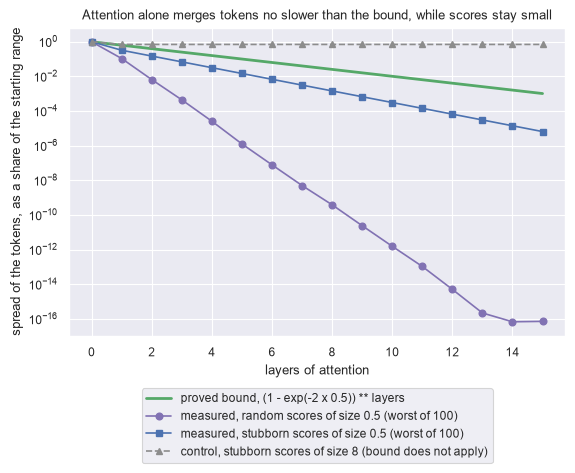

In [3]:
SCORE_BOUND = 0.5
SHRINK_FACTOR = 1 - np.exp(-2 * SCORE_BOUND)
LAYERS = 15
TOKEN_COUNT = 24


def measure_spread(kind, size, seed):
    generator = np.random.default_rng(seed)
    tokens = generator.uniform(-5, 5, size=TOKEN_COUNT)
    start_range = tokens.max() - tokens.min()
    spreads = [1.0]
    for layer in range(LAYERS):
        if kind == "random":
            score_matrix = generator.uniform(-size, size, size=(TOKEN_COUNT, TOKEN_COUNT))
        else:
            above = tokens > np.median(tokens)
            same_side = above[:, None] == above[None, :]
            score_matrix = np.where(same_side, size, -size)
        tokens = apply_attention_layer(tokens, score_matrix)
        spreads.append((tokens.max() - tokens.min()) / start_range)
    return np.array(spreads)


bound_curve = SHRINK_FACTOR ** np.arange(LAYERS + 1)
random_runs = np.array([measure_spread("random", SCORE_BOUND, seed) for seed in range(100)])
stubborn_runs = np.array([measure_spread("stubborn", SCORE_BOUND, seed) for seed in range(100)])
broken_runs = np.array([measure_spread("stubborn", 8.0, seed) for seed in range(100)])
random_worst = (random_runs / bound_curve).max()          # layer 0 is the starting range itself, ratio exactly 1
stubborn_worst = (stubborn_runs / bound_curve).max()
broken_worst = (broken_runs / bound_curve).max()
random_after_one = (random_runs[:, 1:] / bound_curve[1:]).max()          # from the first layer on
stubborn_after_one = (stubborn_runs[:, 1:] / bound_curve[1:]).max()
report("random scores: spread / starting range <= 0.632 ** layers at every layer, 100 runs",
       random_worst <= 1 + 1e-12, f"largest ratio to the bound {random_worst:.3f} (layer 0)")
report("stubborn scores of size 0.5: spread / starting range <= 0.632 ** layers at every layer, 100 runs",
       stubborn_worst <= 1 + 1e-12, f"largest ratio to the bound {stubborn_worst:.3f}")
report("from layer 1 on, stubborn scores come closer to the bound than random ones",
       stubborn_after_one > random_after_one, f"largest ratio {stubborn_after_one:.3f} against {random_after_one:.3f}")
report("control: stubborn scores of size 8 break the hypothesis and exceed the bound (the check can fail)",
       broken_worst > 1, f"largest ratio to the bound {broken_worst:.3g}")

figure, axis = plt.subplots(figsize=(6.4, 4))
layer_axis = np.arange(LAYERS + 1)
axis.plot(layer_axis, bound_curve, color=BOUND, linewidth=2, label="proved bound, (1 - exp(-2 x 0.5)) ** layers")
axis.plot(layer_axis, random_runs.max(axis=0), "o-", color=MODEL, label="measured, random scores of size 0.5 (worst of 100)")
axis.plot(layer_axis, stubborn_runs.max(axis=0), "s-", color=NEAREST, label="measured, stubborn scores of size 0.5 (worst of 100)")
axis.plot(layer_axis, broken_runs.max(axis=0), "^--", color=BEFORE, label="control, stubborn scores of size 8 (bound does not apply)")
axis.set_yscale("log")
axis.set_xlabel("layers of attention")
axis.set_ylabel("spread of the tokens, as a share of the starting range")
axis.set_title("Attention alone merges tokens no slower than the bound, while scores stay small")
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
save_figure(figure, "15-attention-merging")
plt.show()

## Claim 3: an average is no steeper than its steepest member, and no higher than its highest (`lipschitzWith_blend`)

Five members `amplitude * sin(frequency * input + phase)` with slopes `amplitude * frequency` of at most 6, blended
with softmax shares of random scores (non-negative, adding up to one). The slope of each curve is its largest absolute
difference quotient on a grid of 20 001 points over [0, 6], fine enough that the quotient is within a small fraction of a percent of the
true slope for these frequencies. Prediction: in each of 200 draws the blend's slope is at most the steepest member's
slope, and at every input the blend is between the lowest and highest member. Control: shares that add up to 2 (the hypothesis
broken) make the blend twice as high and steep, so its slope exceeds the steepest member's.

[PASS] 200 blends: the slope of the blend is at most the steepest member's slope  (largest ratio 0.992)
[PASS] 200 blends: at every input the blend is between the lowest and highest member  (largest excess 0.0e+00)
[PASS] control: shares adding up to 2 give a blend steeper than the steepest member (the check can fail)  (largest ratio 1.983)
wrote book/figures/15-average-stays-inside.png


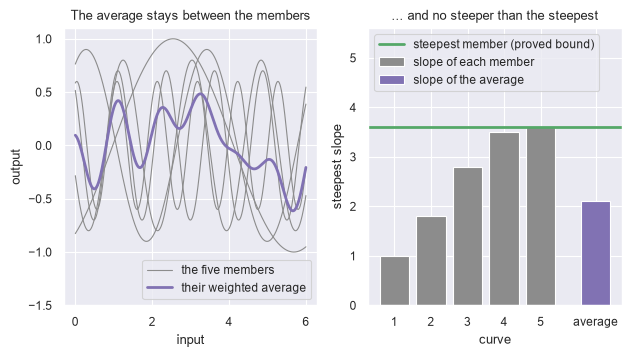

shown draw: steepest member 3.60, the average 2.11


In [4]:
generator = np.random.default_rng(SEED + 1)
GRID = np.linspace(0, 6, 20001)
STEP = GRID[1] - GRID[0]


def measure_slope(curve):
    return np.abs(np.diff(curve)).max() / STEP


worst_slope_ratio = 0.0
worst_range_excess = 0.0
control_ratio = 0.0
for trial in range(200):
    frequencies = generator.uniform(0.5, 6, size=5)
    amplitudes = generator.uniform(0.6, 1.0, size=5)
    phases = generator.uniform(0, 2 * np.pi, size=5)
    members = amplitudes[:, None] * np.sin(frequencies[:, None] * GRID[None, :] + phases[:, None])
    shares = get_softmax(generator.normal(size=5) * 2)
    blend = shares @ members
    steepest = max(measure_slope(member) for member in members)
    worst_slope_ratio = max(worst_slope_ratio, measure_slope(blend) / steepest)
    worst_range_excess = max(worst_range_excess, (blend - members.max(axis=0)).max(), (members.min(axis=0) - blend).max())
    control_ratio = max(control_ratio, measure_slope(2 * blend) / steepest)
report("200 blends: the slope of the blend is at most the steepest member's slope", worst_slope_ratio <= 1 + 1e-12,
       f"largest ratio {worst_slope_ratio:.3f}")
report("200 blends: at every input the blend is between the lowest and highest member", worst_range_excess <= 1e-12,
       f"largest excess {worst_range_excess:.1e}")
report("control: shares adding up to 2 give a blend steeper than the steepest member (the check can fail)",
       control_ratio > 1.2, f"largest ratio {control_ratio:.3f}")

# One draw to show.
generator = np.random.default_rng(SEED + 2)
frequencies = np.array([1.0, 2.0, 3.5, 5.0, 6.0])
amplitudes = np.array([1.0, 0.9, 0.8, 0.7, 0.6])
phases = generator.uniform(0, 2 * np.pi, size=5)
members = amplitudes[:, None] * np.sin(frequencies[:, None] * GRID[None, :] + phases[:, None])
shares = get_softmax(generator.normal(size=5))
blend = shares @ members
member_slopes = np.array([measure_slope(member) for member in members])
blend_slope = measure_slope(blend)

figure, (curve_axis, slope_axis) = plt.subplots(1, 2, figsize=(7.2, 3.6))
for index, member in enumerate(members):
    curve_axis.plot(GRID, member, color=BEFORE, linewidth=0.8, label="the five members" if index == 0 else None)
curve_axis.plot(GRID, blend, color=MODEL, linewidth=2, label="their weighted average")
curve_axis.set_xlabel("input")
curve_axis.set_ylabel("output")
curve_axis.set_title("The average stays between the members")
curve_axis.set_ylim(-1.5, 1.1)
curve_axis.legend(loc="lower right")
slope_axis.bar(np.arange(5), member_slopes, color=BEFORE, label="slope of each member")
slope_axis.axhline(member_slopes.max(), color=BOUND, linewidth=2, label="steepest member (proved bound)")
slope_axis.bar([5.5], [blend_slope], color=MODEL, label="slope of the average")
slope_axis.set_xticks(list(range(5)) + [5.5])
slope_axis.set_xticklabels(["1", "2", "3", "4", "5", "average"])
slope_axis.set_xlabel("curve")
slope_axis.set_ylabel("steepest slope")
slope_axis.set_title("... and no steeper than the steepest")
slope_axis.set_ylim(0, 5.6)
slope_axis.legend(loc="upper left")
save_figure(figure, "15-average-stays-inside")
plt.show()
print(f"shown draw: steepest member {member_slopes.max():.2f}, the average {blend_slope:.2f}")

## Claim 4: with the softmax left out, a head is one step of gradient descent (`prediction_one_step_eq_linearAttention`)

The model is linear in its weights: `prediction = features @ weights`, 6 features, 15 random examples, weights at zero,
loss `0.5 * sum(residual ** 2)`. Take one real gradient step with learning rate 0.05. Its prediction at 50 new inputs must equal
`learning_rate * sum over examples of (example features . new features) * label`, the linear-attention head, to rounding.
Control: keep the softmax, so the shares add up to one. The head then returns a weighted average of the labels, which is
in the labels' range, while the gradient step is not an average at all: the two must disagree.

In [5]:
generator = np.random.default_rng(SEED + 3)
example_features = generator.standard_normal((15, 6))
labels = generator.uniform(-3, 3, size=15)
query_features = generator.standard_normal((50, 6))
learning_rate = 0.05

weights = np.zeros(6)
residual = labels - example_features @ weights
weights = weights + learning_rate * example_features.T @ residual         # one gradient step on 0.5 * sum(residual ** 2)
step_prediction = query_features @ weights
head_output = learning_rate * (query_features @ example_features.T) @ labels   # score = overlap, value = label, no softmax
gap = np.abs(step_prediction - head_output).max()
report("one gradient step from zero predicts what a linear-attention head returns, at 50 new inputs", gap < 1e-12,
       f"largest gap {gap:.1e}; predictions up to {np.abs(step_prediction).max():.2f}")

softmax_head = get_softmax(query_features @ example_features.T) @ labels
softmax_gap = np.abs(step_prediction - softmax_head).max()
report("control: with the softmax kept, the head is an average of the labels and is not the gradient step",
       softmax_gap > 0.1 and softmax_head.min() >= labels.min() and softmax_head.max() <= labels.max(),
       f"largest gap {softmax_gap:.2f}; softmax head in [{softmax_head.min():.2f}, {softmax_head.max():.2f}], "
       f"labels in [{labels.min():.2f}, {labels.max():.2f}]")

[PASS] one gradient step from zero predicts what a linear-attention head returns, at 50 new inputs  (largest gap 1.3e-15; predictions up to 2.15)
[PASS] control: with the softmax kept, the head is an average of the labels and is not the gradient step  (largest gap 2.71; softmax head in [-1.41, 2.98], labels in [-2.39, 2.99])


True

## Claim 5: the ideal denoiser is an average of the training set (`idealDenoiser_mem_convexHull`, `idealDenoiser_isBest`)

Ten one-dimensional training examples. The denoiser scores each example `-(noisy_input - example) ** 2 / (2 * noise_level ** 2)`
and returns the softmax-weighted mean. Prediction: for noise levels from 0.05 to 5 and 500 noisy inputs each, 100 of them far outside the
examples (up to 100 away, against an example range of at most 2), the output is always inside `[smallest example, largest example]`. And it is the best guess: for 500
other candidate outputs per input, the share-weighted squared distance to the examples is never smaller than the denoiser's own. Control:
the plain mean of the examples (equal shares, also inside the range, so that part is no news) must have a larger
share-weighted squared distance than the denoiser on nearly every input.

In [6]:
generator = np.random.default_rng(SEED + 4)
examples = np.sort(generator.uniform(-1, 1, size=10))


def denoise_ideally(noise_level, noisy_input):
    scores = -(noisy_input[:, None] - examples[None, :]) ** 2 / (2 * noise_level ** 2)
    shares = get_softmax(scores)
    return shares @ examples, shares


outside = 0
better_found = 0
plain_loses = 0
cases = 0
for noise_level in (0.05, 0.2, 1.0, 5.0):
    noisy_inputs = np.concatenate([generator.uniform(-2, 2, 400), generator.uniform(-100, 100, 100)])
    denoised, shares = denoise_ideally(noise_level, noisy_inputs)
    outside += int(np.sum((denoised < examples.min() - 1e-12) | (denoised > examples.max() + 1e-12)))
    denoiser_spread = (shares * (examples[None, :] - denoised[:, None]) ** 2).sum(axis=1)
    candidates = generator.uniform(-3, 3, size=(len(noisy_inputs), 500))
    other_spread = (shares[:, None, :] * (examples[None, None, :] - candidates[:, :, None]) ** 2).sum(axis=2)
    better_found += int(np.sum(other_spread < denoiser_spread[:, None] - 1e-12))
    plain_spread = (shares * (examples[None, :] - examples.mean()) ** 2).sum(axis=1)
    cases += len(noisy_inputs)
    plain_loses += int(np.sum(plain_spread > denoiser_spread + 1e-9))
report("the denoiser's output is inside the range of the examples for 4 noise levels and 2000 noisy inputs", outside == 0,
       f"{outside} outside")
report("no other output has a smaller share-weighted squared distance (2000 inputs x 500 candidates)", better_found == 0,
       f"{better_found} better candidates found")
report("control: the equal-share mean is beaten by the denoiser on nearly every input (the check can fail)",
       plain_loses > 0.9 * cases, f"{plain_loses} of {cases}")

[PASS] the denoiser's output is inside the range of the examples for 4 noise levels and 2000 noisy inputs  (0 outside)
[PASS] no other output has a smaller share-weighted squared distance (2000 inputs x 500 candidates)  (0 better candidates found)
[PASS] control: the equal-share mean is beaten by the denoiser on nearly every input (the check can fail)  (1999 of 2000)


True

## Claim 6: a count is the worst thing to ask of an average (`exists_half_count`, `denoiser_two_of_equidistant`, `one_le_slope_mul_dist_of_count`)

Two training examples at positions 0 and 1. The first stands for a hand with five fingers and the second for six, so the
count read-out of a denoiser output `output` is `5 + output`. Three predictions, for noise levels from 0.1 to 1.
**(a)** At the input equally far from both, 0.5, the denoiser returns 0.5 exactly, so the read-out says 5.5
(`denoiser_two_of_equidistant`); and along the path from 0 to 1 the read-out is continuous and increasing, so it passes
through 5.5 (`exists_half_count`). **(b)** The read-out at the two examples differs by `gap`; its steepest slope on the path
times the distance 1 must be at least `gap` (`one_le_slope_mul_dist_of_count`, in its mean-value form, since the ideal denoiser only
approaches 5 and 6). The steepest slope should be `1 / (4 * noise_level ** 2)`, at the middle, which I check to 0.1 percent.
**(c)** A head over `total` tokens, `copies` of them marked with value 1 and the rest 0, with equal scores, returns
`copies / total`: the same for 6 of 20 as for 3 of 10. Going from `copies` to `copies + 1` moves the output by exactly
`1 / total`. What would count against this: a half count missing from the path, a gap above one, or an output that depended
on the number of copies rather than their share.

noise level 0.1: read-out at 0.5 is 5.500000000000, crosses 5.5 at 0.5000; gap between the examples 1.0000, steepest slope 25.000, 1/(4 noise^2) = 25.000
noise level 0.2: read-out at 0.5 is 5.500000000000, crosses 5.5 at 0.5000; gap between the examples 1.0000, steepest slope 6.250, 1/(4 noise^2) = 6.250
noise level 0.5: read-out at 0.5 is 5.500000000000, crosses 5.5 at 0.5000; gap between the examples 0.7616, steepest slope 1.000, 1/(4 noise^2) = 1.000
noise level 1.0: read-out at 0.5 is 5.500000000000, crosses 5.5 at 0.5000; gap between the examples 0.2449, steepest slope 0.250, 1/(4 noise^2) = 0.250
[PASS] (a) at the equidistant input the read-out is exactly 5.5, for 4 noise levels
[PASS] (a) the read-out never decreases along the path (it saturates to rounding at the ends for small noise) and is closest to 5.5 at 0.5
[PASS] (b) steepest slope x distance 1 >= the change between the examples, for every noise level  (gaps [1.0, 1.0, 0.762, 0.245])
[PASS] (b) the steepest slope is 1 / 

wrote book/figures/15-count-against-copies.png


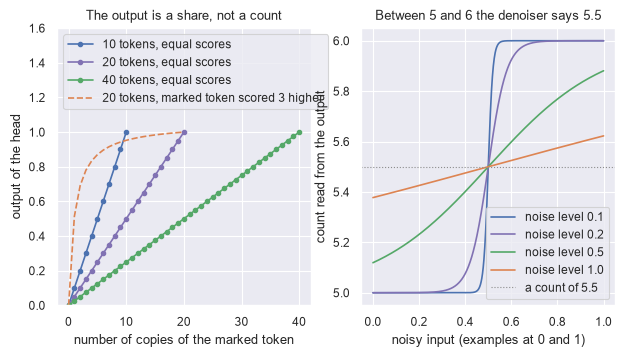

In [7]:
PATH = np.linspace(0, 1, 100001)
PATH_STEP = PATH[1] - PATH[0]
TWO_EXAMPLES = np.array([0.0, 1.0])
NOISE_LEVELS = (0.1, 0.2, 0.5, 1.0)


def read_count(positions, noise_level):
    scores = -(positions[:, None] - TWO_EXAMPLES[None, :]) ** 2 / (2 * noise_level ** 2)
    return 5 + get_softmax(scores) @ TWO_EXAMPLES


rows = []
for noise_level in NOISE_LEVELS:
    path_values = read_count(PATH, noise_level)
    middle = float(read_count(np.array([0.5]), noise_level)[0])
    crossing = PATH[np.argmin(np.abs(path_values - 5.5))]
    steepest = np.abs(np.diff(path_values)).max() / PATH_STEP
    gap = path_values[-1] - path_values[0]
    increasing = bool(np.all(np.diff(path_values) >= 0))
    rows.append((noise_level, middle, crossing, steepest, gap, increasing))
    print(f"noise level {noise_level}: read-out at 0.5 is {middle:.12f}, crosses 5.5 at {crossing:.4f}; "
          f"gap between the examples {gap:.4f}, steepest slope {steepest:.3f}, 1/(4 noise^2) = {1 / (4 * noise_level ** 2):.3f}")
report("(a) at the equidistant input the read-out is exactly 5.5, for 4 noise levels",
       all(abs(row[1] - 5.5) < 1e-12 for row in rows))
report("(a) the read-out never decreases along the path (it saturates to rounding at the ends for small noise) and is closest to 5.5 at 0.5",
       all(row[5] and abs(row[2] - 0.5) < 1e-4 for row in rows))
report("(b) steepest slope x distance 1 >= the change between the examples, for every noise level",
       all(row[3] * 1.0 >= row[4] for row in rows), f"gaps {[round(float(row[4]), 3) for row in rows]}")
report("(b) the steepest slope is 1 / (4 noise_level ** 2) to 0.1 percent",
       all(abs(row[3] * 4 * row[0] ** 2 - 1) < 1e-3 for row in rows))
report("(b) the wide average (noise level 1) is far from telling 5 from 6: gap under half",
       rows[-1][4] < 0.5, f"gap {rows[-1][4]:.3f}")

TOTAL_TOKENS = (10, 20, 40)


def apply_head_to_copies(copies, total, mark_score):
    weight = np.exp(mark_score)
    return copies * weight / (copies * weight + (total - copies))


copy_axis = {total: np.arange(0, total + 1) for total in TOTAL_TOKENS}
plain = {total: apply_head_to_copies(copy_axis[total], total, 0.0) for total in TOTAL_TOKENS}
report("(c) the output is the share: 3 of 10 and 6 of 20 both give 0.3",
       abs(apply_head_to_copies(3, 10, 0.0) - apply_head_to_copies(6, 20, 0.0)) < 1e-15
       and abs(apply_head_to_copies(3, 10, 0.0) - 0.3) < 1e-15)
steps = {total: np.diff(plain[total]) for total in TOTAL_TOKENS}
report("(c) one more copy moves the output by exactly 1 / total, so the step between counts shrinks as tokens are added",
       all(np.allclose(steps[total], 1 / total) for total in TOTAL_TOKENS),
       "steps " + ", ".join(f"{steps[total][0]:.4f} at {total} tokens" for total in TOTAL_TOKENS))
sharp = apply_head_to_copies(copy_axis[20], 20, 3.0)
report("(c) a larger score on the marked token bends the curve, but one more copy still moves the output by less than one",
       bool(np.all(np.diff(sharp) < 1)), f"largest step {np.diff(sharp).max():.3f} with the mark scored 3 higher")

figure, (copy_plot, readout_plot) = plt.subplots(1, 2, figsize=(7.2, 3.6))
for total, color in zip(TOTAL_TOKENS, (NEAREST, MODEL, BOUND)):
    copy_plot.plot(copy_axis[total], plain[total], "o-", markersize=3, color=color, label=f"{total} tokens, equal scores")
copy_plot.plot(copy_axis[20], sharp, "--", color=VERTICAL, label="20 tokens, marked token scored 3 higher")
copy_plot.set_xlabel("number of copies of the marked token")
copy_plot.set_ylabel("output of the head")
copy_plot.set_title("The output is a share, not a count")
copy_plot.set_ylim(0, 1.6)
copy_plot.legend(loc="upper left")
for noise_level, color in zip(NOISE_LEVELS, (NEAREST, MODEL, BOUND, VERTICAL)):
    readout_plot.plot(PATH[::100], read_count(PATH[::100], noise_level), color=color, label=f"noise level {noise_level}")
readout_plot.axhline(5.5, color=BEFORE, linewidth=0.8, linestyle=":", label="a count of 5.5")
readout_plot.set_xlabel("noisy input (examples at 0 and 1)")
readout_plot.set_ylabel("count read from the output")
readout_plot.set_title("Between 5 and 6 the denoiser says 5.5")
readout_plot.legend(loc="lower right")
save_figure(figure, "15-count-against-copies")
plt.show()

## Claim 7: the error of an ensemble is the members' average error minus their spread (`sq_blend_sub`, `sq_blend_sub_le`)

Six members' predictions, shares adding up to one, a label. Prediction: `(blend - label) ** 2 = sum(share * (prediction -
label) ** 2) - sum(share * (prediction - blend) ** 2)` to rounding over 1000 draws, and, with non-negative shares, the ensemble's
squared error is at most the members' average. Control: allow shares that are not all non-negative (still adding up to one). The
inequality must then fail in some draws, because the proof needs non-negative shares.

In [8]:
generator = np.random.default_rng(SEED + 5)
largest_identity_gap = 0.0
inequality_breaks = 0
negative_breaks = 0
for trial in range(1000):
    predictions = generator.normal(size=6) * 2
    label = generator.normal() * 2
    shares = get_softmax(generator.normal(size=6))
    blend = shares @ predictions
    average_error = shares @ (predictions - label) ** 2
    spread = shares @ (predictions - blend) ** 2
    largest_identity_gap = max(largest_identity_gap, abs((blend - label) ** 2 - (average_error - spread)))
    inequality_breaks += (blend - label) ** 2 > average_error + 1e-12
    signed = generator.normal(size=6)
    signed = signed / signed.sum() if abs(signed.sum()) > 0.5 else shares      # adds up to one, may be negative
    signed_blend = signed @ predictions
    negative_breaks += (signed_blend - label) ** 2 > signed @ (predictions - label) ** 2 + 1e-12
report("1000 draws: blend error = average error - spread, to rounding", largest_identity_gap < 1e-10,
       f"largest gap {largest_identity_gap:.1e}")
report("1000 draws with non-negative shares: the ensemble is never worse than the members' average", inequality_breaks == 0,
       f"{inequality_breaks} violations")
report("control: shares that may be negative break the inequality in some draws (the check can fail)", negative_breaks > 0,
       f"{negative_breaks} of 1000 draws")

[PASS] 1000 draws: blend error = average error - spread, to rounding  (largest gap 2.1e-14)
[PASS] 1000 draws with non-negative shares: the ensemble is never worse than the members' average  (0 violations)
[PASS] control: shares that may be negative break the inequality in some draws (the check can fail)  (392 of 1000 draws)


True

## Claim 8: a lower temperature never lowers the average score, and concentrates on the top (`expectedScore_softmax_mono`, `one_sub_softmax_div_le`)

Eight answers with random scores. Sample from `softmax(scores / temperature)`. Prediction: over 500 score vectors and
temperatures from 4 down to 0.05 in 40 steps, the average score never falls from one step to the next (to rounding). Also,
if the top score leads every other by at least `gap` (here the actual gap to the runner-up), the share missing from the top is at most
`(answers - 1) * exp(-gap / temperature)`, checked at each temperature. Control: the bound with `exp(-2 * gap / temperature)`
is not the theorem's, and must be violated somewhere. Last, the **variety** (entropy of the shares) is measured at each step:
this is not a claim of the chapter, only a count of how often it fell at every step in these draws.

In [9]:
generator = np.random.default_rng(SEED + 6)
TEMPERATURES = np.geomspace(4.0, 0.05, 40)
ANSWER_COUNT = 8
score_drops = 0
bound_violations = 0
broken_bound_violations = 0
entropy_always_fell = 0
checks = 0
mean_scores = []
mean_entropies = []
for trial in range(500):
    scores = generator.normal(size=ANSWER_COUNT) * 2
    ordered = np.sort(scores)
    gap = ordered[-1] - ordered[-2]
    average_scores = []
    entropies = []
    for temperature in TEMPERATURES:
        shares = get_softmax(scores / temperature)
        average_scores.append(shares @ scores)
        entropies.append(-(shares * np.log(shares + 1e-300)).sum())
        top_miss = 1 - shares[np.argmax(scores)]
        bound_violations += top_miss > (ANSWER_COUNT - 1) * np.exp(-gap / temperature) + 1e-12
        broken_bound_violations += top_miss > (ANSWER_COUNT - 1) * np.exp(-2 * gap / temperature) + 1e-12
        checks += 1
    score_drops += int(np.sum(np.diff(average_scores) < -1e-12))
    entropy_always_fell += bool(np.all(np.diff(entropies) <= 1e-12))
    mean_scores.append(average_scores)
    mean_entropies.append(entropies)
report("500 score vectors: the average score never falls as the temperature falls", score_drops == 0,
       f"{score_drops} drops in {500 * (len(TEMPERATURES) - 1)} steps")
report("the share missing from the top is at most (answers - 1) * exp(-gap / temperature)", bound_violations == 0,
       f"{bound_violations} violations in {checks} checks")
report("control: the bound with exp(-2 * gap / temperature) is violated somewhere (the check can fail)",
       broken_bound_violations > 0, f"{broken_bound_violations} violations in {checks} checks")
print(f"measured, not a claim: the variety fell at every temperature step in {entropy_always_fell} of 500 draws; "
      f"mean score {np.mean(mean_scores, axis=0)[0]:.3f} at temperature 4 and {np.mean(mean_scores, axis=0)[-1]:.3f} at 0.05, "
      f"mean variety {np.mean(mean_entropies, axis=0)[0]:.3f} and {np.mean(mean_entropies, axis=0)[-1]:.3f}")

[PASS] 500 score vectors: the average score never falls as the temperature falls  (0 drops in 19500 steps)
[PASS] the share missing from the top is at most (answers - 1) * exp(-gap / temperature)  (0 violations in 20000 checks)
[PASS] control: the bound with exp(-2 * gap / temperature) is violated somewhere (the check can fail)  (8846 violations in 20000 checks)
measured, not a claim: the variety fell at every temperature step in 500 of 500 draws; mean score 0.829 at temperature 4 and 2.757 at 0.05, mean variety 1.981 and 0.068


## Claim 9: copying the nearest label is wrong by at most the slope times the distance (`abs_sub_nearest_le`)

The truth is `sin(3 * input) + 0.5 * sin(7 * input)`, whose slope is at most `3 + 3.5 = 6.5`. Twenty training inputs in [0, 6], 5000
queries in [0, 6]. Prediction: for every query, `|truth(query) - truth(nearest training input)| <= 6.5 * distance to the
nearest`. The distance here is along the input axis, so the vertical error of the copied label is what is bounded; both are
reported. Control: a truth that jumps (a step of height 1 at 3) has no slope limit; copying the nearest label must then be wrong
by 1 at a query a hair's breadth from a training input's side of the jump, above `6.5 * distance`.

In [10]:
generator = np.random.default_rng(SEED + 7)
SLOPE_LIMIT = 6.5


def get_truth(inputs):
    return np.sin(3 * inputs) + 0.5 * np.sin(7 * inputs)


training_inputs = np.sort(generator.uniform(0, 6, size=20))
queries = generator.uniform(0, 6, size=5000)
nearest_index = np.abs(queries[:, None] - training_inputs[None, :]).argmin(axis=1)
distance = np.abs(queries - training_inputs[nearest_index])
vertical_error = np.abs(get_truth(queries) - get_truth(training_inputs[nearest_index]))
report("5000 queries: the error of the nearest label is at most slope limit x distance to the nearest input",
       bool(np.all(vertical_error <= SLOPE_LIMIT * distance + 1e-12)),
       f"largest error {vertical_error.max():.3f} at distance {distance[vertical_error.argmax()]:.3f}; "
       f"largest error / (limit x distance) {np.max(vertical_error / (SLOPE_LIMIT * distance)):.3f}")


def get_jump(inputs):
    return (inputs > 3.0).astype(float)


close_query = np.array([3.0001])                # just right of the jump
jump_training_inputs = np.array([2.9999, 4.0])  # a training input just left of the jump is the nearest
close_nearest = np.abs(close_query[:, None] - jump_training_inputs[None, :]).argmin(axis=1)
jump_error = np.abs(get_jump(close_query) - get_jump(jump_training_inputs[close_nearest]))[0]
jump_distance = np.abs(close_query - jump_training_inputs[close_nearest])[0]
report("control: a jump in the truth breaks the bound (the check can fail)",
       jump_error > SLOPE_LIMIT * jump_distance,
       f"vertical error {jump_error:.1f} at distance {jump_distance:.4f}, against limit x distance {SLOPE_LIMIT * jump_distance:.4f}")

[PASS] 5000 queries: the error of the nearest label is at most slope limit x distance to the nearest input  (largest error 1.559 at distance 0.339; largest error / (limit x distance) 0.859)
[PASS] control: a jump in the truth breaks the bound (the check can fail)  (vertical error 1.0 at distance 0.0002, against limit x distance 0.0013)


True